### define global variables

In [1]:
model_order = [
    "Cohere CAT+",
    "Command A+",
    "CUNI-EdUKate",
    "CUNI-MH-v3",
    "DeepSeek V4 Pro",
    "Dubformer",
    "Gemini 3.1 Pro",
    "Gemma 4 - 4B",
    "Gemma 4 - 31B",
    "GLM 4 - 9B",
    "GoogleTranslate",
    "GPT 5.5",
    "GPT OSS 20B",
    "GPT OSS 120B",
    "Ministral 3 - 14B",
    "Mistral Medium 3.5",
    "Qingqiu-MT-9B",
    "Qwen 3.5 - 9b",
    "Qwen 3.6 - 27b",
    "SalamandraTA",
    "Tiny Aya Global",
    "Tower 9B",
    "TRIVE",
    "UvA-MT",
]

In [2]:
import pandas as pd

# import original test set
hom_testset = pd.read_csv("../df_hom.tsv", sep ="\t")


# get term matches (list of binary matches) for the target term
hom_matches = pd.read_csv(
    "./wmt_json_translations/results/hom/tgt_term_gold.csv",
    sep=",",
    encoding="utf-8-sig"
)

cols = model_order
hom_matches = hom_matches[cols]

hom_matches_list = hom_matches.map(lambda x: 0 if str(x).strip() in ["[]", "", "nan"] else 1)



# get term matches (list of binary matches) for the target term
var_matches = pd.read_csv(
    "./wmt_json_translations/results/var/tgt_term_gold.csv",
    sep=",",
    encoding="utf-8-sig"
)

cols = model_order
var_matches = var_matches[cols]

var_matches_list = var_matches.map(lambda x: 0 if str(x).strip() in ["[]", "", "nan"] else 1)
# get term matches (list of binary matches) for the cumulated distractors
# Load the three distractor match files
# Cumulated distractor match:
# 1 if there is at least one match in AT, DE, or CH
# 0 otherwise
hom_matches_distractor = pd.read_csv(
    "./wmt_json_translations/results/hom/tgt_term_homonym.csv",
    sep=",",
    encoding="utf-8-sig"
)[cols]

hom_distractors_matches_list = hom_matches_distractor.map(lambda x: 0 if str(x).strip() in ["[]", "", "nan"] else 1)


In [3]:
#upload training history and save in a variable
import csv
import pandas as pd

results_hom = pd.read_csv("./wmt_json_translations/results/term_accuracy_rates_hom.tsv", sep="\t")
results_hom.columns = results_hom.columns.str.strip()
results_hom["model"] = results_hom["model"].astype(str).str.strip()

# Filter and reorder to match cols
results = results_hom[results_hom["model"].isin(cols)].copy()
results["model"] = pd.Categorical(results["model"], categories=cols, ordered=True)
results = results.sort_values("model").reset_index(drop=True)


# Validate parallel and synthetic contexts performances

In [4]:
def compare_parallel_contexts(hom_testset, hom_matches_list):
    """
    Compare model performance between synthetic and parallel contexts.

    The function identifies paired instance_ids using in the test set, where human parallel
    examples are marked with the `_par` suffix. It then separates synthetic
    and parallel rows, aligns them by their shared base ID, and calculates
    the percentage of positive matches for each model in both sets.

    Parameters
    ----------
    hom_testset : pandas.DataFrame
        Eurac Test set.

    hom_matches_list : pandas.DataFrame
        Table with term matches (derived from term_finder pipeline). Rows are testset instances, columns are models
        Matches are 1, non matches are 0

    Returns
    -------
    pandas.DataFrame
        A table with one row per model and columns:
        `model`, `synthetic`, and `parallel` contexts.
    """

    # Copies
    hom_testset_op = hom_testset.copy()
    hom_matches_list_op = hom_matches_list.copy()

    # Attach IDs to result table, assuming rows are in the same order as hom_testset
    hom_matches_list_op["instance_id"] = hom_testset_op["instance_id"].values

    # Create base ID and parallel flag
    hom_testset_op["base_id"] = hom_testset_op["instance_id"].str.replace(
        r"_par$", "", regex=True
    )
    hom_testset_op["is_par"] = hom_testset_op["instance_id"].str.endswith("_par")

    # Keep only IDs that have both base and _par versions
    paired_base_ids = (
        hom_testset_op
        .groupby("base_id")["is_par"]
        .nunique()
    )

    paired_base_ids = paired_base_ids[paired_base_ids == 2].index

    paired_map = hom_testset_op[
        hom_testset_op["base_id"].isin(paired_base_ids)
    ][["instance_id", "base_id", "is_par"]]

    # Add base_id and is_par to result table
    all_par_results = hom_matches_list_op.merge(
        paired_map,
        on="instance_id",
        how="inner"
    )

    # Identify model columns
    metadata_cols = {"instance_id", "base_id", "is_par"}
    model_cols = [c for c in all_par_results.columns if c not in metadata_cols]

    # Synthetic / non-parallel rows
    non_par_results = (
        all_par_results[all_par_results["is_par"] == False]
        .set_index("base_id")[model_cols]
        .sort_index()
    )

    # Parallel rows
    par_results = (
        all_par_results[all_par_results["is_par"] == True]
        .set_index("base_id")[model_cols]
        .sort_index()
    )

    # Align both tables by shared base_id
    common_ids = non_par_results.index.intersection(par_results.index)

    non_par_aligned = non_par_results.loc[common_ids]
    par_aligned = par_results.loc[common_ids]
    #print(par_aligned)
    
    
    # Percentage of 1s for each model in each table
    final_results = pd.DataFrame({
        "synthetic": non_par_aligned.mean() * 100,
        "parallel": par_aligned.mean() * 100
    })

    # Models as rows
    final_results = final_results.reset_index()
    final_results.columns = ["model", "synthetic", "parallel"]

    return final_results

import matplotlib.pyplot as plt
import numpy as np


def plot_parallel_context_results(results, figsize=(12, 6)):
    """
    Plot synthetic vs. parallel context match success percentages by model.

    Parameters
    ----------
    results : pandas.DataFrame
        Output of compare_parallel_contexts(), with columns:
        'model', 'synthetic', and 'parallel'.

    figsize : tuple, optional
        Figure size.

    Returns
    -------
    fig, ax
        Matplotlib figure and axes objects.
    """

    x = np.arange(len(results))

    fig, ax = plt.subplots(figsize=figsize)

    # Vertical line connecting the two scores for each model
    for i in x:
        ax.plot(
            [i, i],
            [results.loc[i, "synthetic"], results.loc[i, "parallel"]],
            color="gray",
            linewidth=1.5,
            alpha=0.7,
            zorder=1
        )

    # Synthetic-context points
    ax.scatter(
        x,
        results["synthetic"],
        marker="o",
        color="tab:blue",
        s=70,
        label="Synthetic source",
        zorder=2
    )

    # Parallel-context points
    ax.scatter(
        x,
        results["parallel"],
        marker="D",
        color="tab:orange",
        s=70,
        label="Parallel source",
        zorder=2
    )

    ax.set_xticks(x)
    ax.set_xticklabels(results["model"], rotation=45, ha="right")

    ax.set_ylabel("Term accuracy")
    ax.set_xlabel("Model")
    ax.set_ylim(0, 100)

    ax.legend()
    ax.grid(axis="y", linestyle="--", alpha=0.3)

    fig.tight_layout()

    return fig, ax

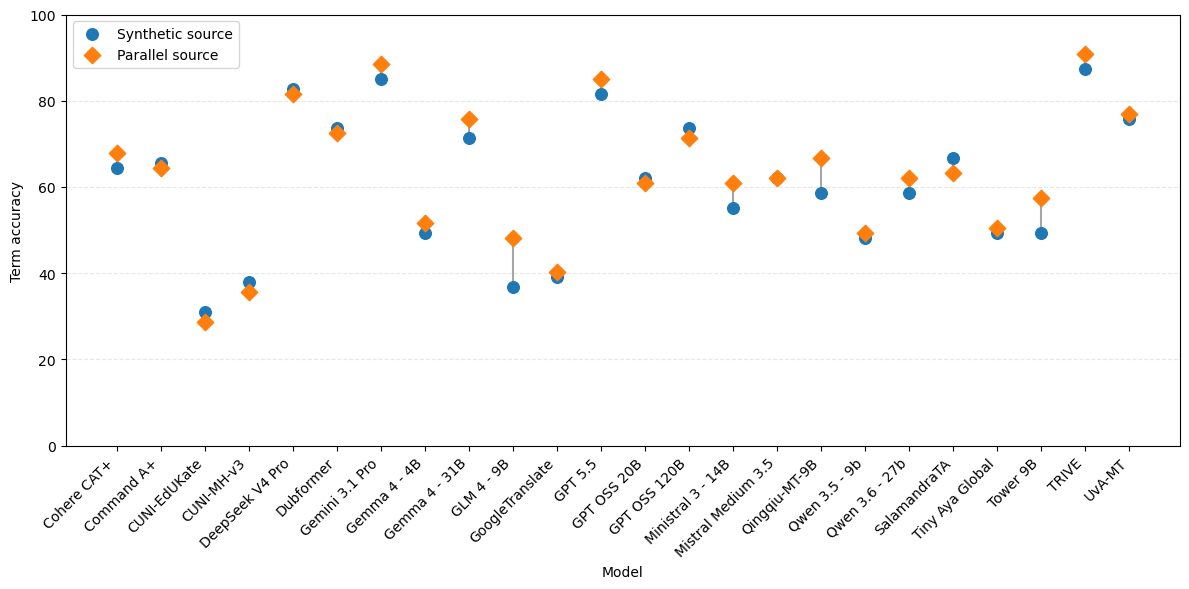

In [5]:
par_synth_results = compare_parallel_contexts(
    hom_testset=hom_testset,
    hom_matches_list=hom_matches_list
)

fig, ax = plot_parallel_context_results(par_synth_results)
#plt.show()

In [6]:
fig.savefig("./results_tables_and_plots/1_synth_validation_ta_hom.png", dpi=300, bbox_inches="tight")
par_synth_results.to_csv("./results_tables_and_plots/1_synth_validation_ta_hom.tsv", sep="\t", index=False)


In [7]:
par_synth_results

,model,synthetic,parallel
0,Cohere CAT+,64.367816,67.816092
1,Command A+,65.517241,64.367816
2,CUNI-EdUKate,31.034483,28.735632
3,CUNI-MH-v3,37.931034,35.632184
4,DeepSeek V4 Pro,82.758621,81.609195
5,Dubformer,73.563218,72.413793
6,Gemini 3.1 Pro,85.057471,88.505747
7,Gemma 4 - 4B,49.425287,51.724138
8,Gemma 4 - 31B,71.264368,75.862069
9,GLM 4 - 9B,36.781609,48.275862


# Separate par and synth contexts

In [8]:
# Find rows in hom_testset where instance_id ends with "_par"
par_idx = hom_testset.index[
    hom_testset["instance_id"].str.endswith("_par", na=False)
]

# Original hom_testset without _par rows
hom_testset_synth = hom_testset.drop(index=par_idx).copy()

# New dataframe with only _par rows
hom_testset_par = hom_testset.loc[par_idx].copy()

# Apply the same split to other aligned variables
hom_matches_list_par = hom_matches_list.loc[par_idx].copy()
hom_matches_list_synth = hom_matches_list.drop(index=par_idx).copy()

# Apply the same split to distractor matches
hom_distractors_matches_list_par = hom_distractors_matches_list.loc[par_idx].copy()
hom_distractors_matches_list_synth = hom_distractors_matches_list.drop(index=par_idx).copy()


In [10]:
hom_testset_synth['variety'].value_counts()

variety
['DE']          362
['Südtirol']    346
['CH']          256
['AT']          250
Name: count, dtype: int64

# Plot term accuracy, bleu and chrf

In [9]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np


def plot_term_accuracy(hom_matches_list, hom_distractors_matches_list,
                       figsize=(12, 6)):
    """
    Plot cumulative distractor match rate and final term accuracy
    for each model.

    Final term accuracy:
        target match = 1 AND distractor match = 0

    Parameters
    ----------
    hom_matches_list : pandas.DataFrame
        Binary target-term matches.
        Rows are test-set instances and columns are models.

    hom_distractors_matches_list : pandas.DataFrame
        Binary cumulative distractor matches.
        1 = at least one distractor matched
        0 = no distractor matched.

    figsize : tuple, optional
        Figure size.

    Returns
    -------
    fig, ax : matplotlib Figure and Axes

    accuracy_df : pandas.DataFrame
        Table containing model, term accuracy,
        and cumulative distractor match rate.
    """

    # Align rows and models
    common_index = hom_matches_list.index.intersection(
        hom_distractors_matches_list.index
    )

    common_cols = hom_matches_list.columns.intersection(
        hom_distractors_matches_list.columns
    )

    target = hom_matches_list.loc[common_index, common_cols]
    distractor = hom_distractors_matches_list.loc[
        common_index, common_cols
    ]

    # Percentage of examples containing at least one distractor match
    distractor_rate = distractor.mean() * 100

    # Correct target AND no distractor
    term_accuracy = (
        (target == 1) & (distractor == 0)
    ).mean() * 100

    # Results dataframe
    accuracy_df = pd.DataFrame({
        "model": common_cols,
        "term_accuracy": term_accuracy.values,
        "distractor_match_rate": distractor_rate.values
    })

    x = np.arange(len(accuracy_df))

    fig, ax = plt.subplots(figsize=figsize)

    # Vertical line connecting both values for every model
    for i in x:
        ax.plot(
            [i, i],
            [
                accuracy_df.loc[i, "distractor_match_rate"],
                accuracy_df.loc[i, "term_accuracy"]
            ],
            color="gray",
            linewidth=1.5,
            alpha=0.7,
            zorder=1
        )

    # Term accuracy
    ax.scatter(
        x,
        accuracy_df["term_accuracy"],
        marker="o",
        color="green",
        s=70,
        label="Term accuracy",
        zorder=2
    )

    # Cumulative distractor match rate
    ax.scatter(
        x,
        accuracy_df["distractor_match_rate"],
        marker="D",
        color="red",
        s=70,
        label="Distractor insertion rate",
        zorder=2
    )

    ax.set_xticks(x)
    ax.set_xticklabels(
        accuracy_df["model"],
        rotation=45,
        ha="right"
    )

    ax.set_xlabel("Model")
    ax.set_ylabel("Term accuracy")
    ax.set_title(
        "Results for the HOM subset"
    )

    ax.set_ylim(0, 100)

    ax.legend()
    ax.grid(axis="y", linestyle="--", alpha=0.3)

    fig.tight_layout()

    return fig, ax, accuracy_df

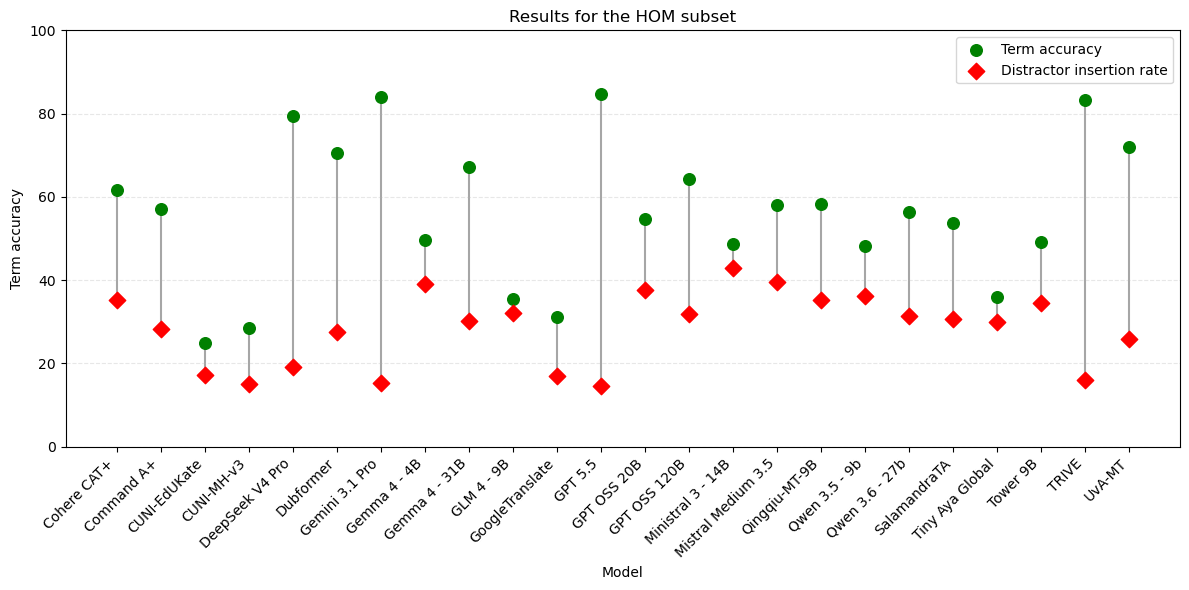

In [10]:
fig, ax, term_accuracy_df = plot_term_accuracy(
    hom_matches_list_synth,
    hom_distractors_matches_list_synth
)

plt.show()

In [11]:
fig.savefig("./results_tables_and_plots/2_ta_hom.png", dpi=300, bbox_inches="tight")


In [14]:
term_accuracy_df

,model,term_accuracy,distractor_match_rate
0,Cohere CAT+,61.696870,35.255354
1,Command A+,57.166392,28.171334
2,CUNI-EdUKate,24.958814,17.298188
3,CUNI-MH-v3,28.583196,15.156507
4,DeepSeek V4 Pro,79.489292,19.028007
5,Dubformer,70.593081,27.429984
6,Gemini 3.1 Pro,84.019769,15.321252
7,Gemma 4 - 4B,49.670511,38.962109
8,Gemma 4 - 31B,67.215815,30.148270
9,GLM 4 - 9B,35.502471,32.207578


# Term accuracy by variety

# big models have a higher delta for sudtirol, otherwise not present

In [16]:
# Count each individual legal domain without exploding the dataframe
variety_counts = (
    hom_testset_synth["variety"]
    .dropna()
    .str.split("|")
    .apply(lambda x: [d.strip() for d in x])
    .sum()
)

variety_counts = pd.Series(variety_counts).value_counts()

variety_counts

['DE']          362
['Südtirol']    346
['CH']          256
['AT']          250
Name: count, dtype: int64

In [17]:
def term_accuracy_by_variety(
    hom_testset,
    hom_matches,
    variety_column="variety",
    decimals=2
):
    """
    Create a wide terminology-accuracy table by variety.

    Each distinct variety value is evaluated separately.
    No grouping of values is applied.
    A final Mean row is added across models.
    """

    if len(hom_testset) != len(hom_matches):
        raise ValueError(
            f"Length mismatch: test set = {len(hom_testset)}, "
            f"matches = {len(hom_matches)}"
        )

    results = []

    # Keep every distinct variety value
    variety_values = (
        hom_testset[variety_column]
        .dropna()
        .unique()
    )

    # Sort where possible
    try:
        variety_values = sorted(variety_values)
    except TypeError:
        pass

    for value in variety_values:

        mask = hom_testset[variety_column] == value

        variety_matches = hom_matches.loc[mask]

        variety_accuracy = variety_matches.mean() * 100

        for model, accuracy in variety_accuracy.items():
            results.append({
                "model": model,
                "variety": value,
                "term_accuracy": accuracy
            })

    long_df = pd.DataFrame(results)

    table_df = long_df.pivot(
        index="model",
        columns="variety",
        values="term_accuracy"
    )

    table_df = table_df[variety_values].round(decimals)

    table_df.index.name = None
    table_df.columns.name = None

    # Mean accuracy across models for each variety
    table_df.loc["Mean"] = (
        table_df.mean(axis=0).round(decimals)
    )

    return table_df

In [18]:
variety_accuracy_table = term_accuracy_by_variety(
    hom_testset=hom_testset_synth,
    hom_matches=hom_matches_list_synth,
    variety_column="variety",
    decimals=2
)

variety_accuracy_table

,['AT'],['CH'],['DE'],['Südtirol']
CUNI-EdUKate,21.60,31.64,27.07,22.25
CUNI-MH-v3,26.00,34.77,28.45,28.03
Cohere CAT+,68.00,65.23,63.81,62.43
Command A+,64.80,58.20,49.45,62.14
DeepSeek V4 Pro,82.80,81.64,82.04,75.72
Dubformer,77.20,71.48,74.59,65.90
GLM 4 - 9B,34.00,33.59,39.50,38.15
GPT 5.5,88.80,87.50,86.74,80.06
GPT OSS 120B,68.40,63.67,66.30,64.16
GPT OSS 20B,56.40,54.69,53.87,57.51


In [30]:
variety_accuracy_table = variety_accuracy_table[["['Südtirol']","['DE']",	 "['AT']",	"['CH']"	]]
#variety_accuracy_table.rename_axis("model").reset_index().to_csv("./results_tables_and_plots/ta_rel.tsv", sep="\t", index=False)

In [33]:
variety_accuracy_table.columns = ['Südtirol', 'DE', 'AT', 'CH']

In [35]:
variety_accuracy_table.rename_axis("model").reset_index().to_csv("./results_tables_and_plots/ta_hom.tsv", sep="\t", index=False)

# plot blue 

In [19]:
from sacrebleu.metrics import BLEU, CHRF

In [20]:
import pandas as pd
#import translations

from pathlib import Path

hypotheses_dir='./wmt_json_translations/translations/hom',

translations_folder_hom = Path(
    "./wmt_json_translations/translations/hom"
)

# Read every .txt file in the folder
translation_columns = {}

for txt_file in sorted(translations_folder_hom.glob("*.txt")):
    model_name = txt_file.stem

    with open(txt_file, "r", encoding="utf-8") as f:
        translations = [line.rstrip("\n") for line in f]

    translation_columns[model_name] = translations


# Check that all models have the same number of translations
lengths = {
    model: len(translations)
    for model, translations in translation_columns.items()
}

if len(set(lengths.values())) != 1:
    raise ValueError(
        f"Translation files have different numbers of rows: {lengths}"
    )


# Create dataframe:
# columns = models
# rows = hypothesis translations
hyp_translations_hom = pd.DataFrame(translation_columns)

hyp_translations_hom_synth = hyp_translations_hom.drop(index=par_idx).copy()

In [21]:
 def score_corpus(hypotheses, references, metric='chrf', n_bootstrap=1000):
    """
    Compute corpus-level BLEU or chrF for every model.

    Parameters
    ----------
    hypotheses : str, Path, or pd.DataFrame
        Either:
          - a directory containing one .txt file per model (filename = model name), or
          - a DataFrame with one column per model, one row per segment.
    references : str, Path, or list[str]
        Either:
          - a path to a TSV with a 'context' column holding reference sentences, or
          - a list of reference sentences (one per segment).
    metric : str
        'bleu' or 'chrf'.
    n_bootstrap : int
        Bootstrap resamples for confidence intervals.

    Returns
    -------
    scores : dict[str, float]
        model_name -> corpus score.
    results_df : pd.DataFrame
        New DataFrame with columns ['model', metric], one row per model.
    """
    assert metric in ('bleu', 'chrf'), "metric must be 'bleu' or 'chrf'"

    # --- load reference ---
    if isinstance(references, (list, tuple, pd.Series)):
        references = [str(r) for r in references]
    else:
        reference_path = Path(references)
        if not reference_path.exists():
            raise FileNotFoundError(f"Reference file not found: {reference_path}")

        references_df = pd.read_csv(reference_path, sep='\t', encoding='utf-8')
        if 'context' not in references_df.columns:
            raise ValueError(
                f"Column 'context' not found in {reference_path}. "
                f"Available columns: {list(references_df.columns)}"
            )
        references = references_df['context'].astype(str).tolist()

    # --- init scorer ---
    if metric == 'bleu':
        scorer = BLEU(tokenize='13a')
        decimals = 2
    else:
        scorer = CHRF(word_order=2)
        decimals = 4

    # --- build model_name -> list[str] mapping from either input type ---
    model_hyps = {}

    if isinstance(hypotheses, pd.DataFrame):
        for model_name in hypotheses.columns:
            model_hyps[model_name] = hypotheses[model_name].astype(str).tolist()

    else:
        hypotheses_dir = Path(hypotheses)
        if not hypotheses_dir.is_dir():
            raise NotADirectoryError(f"Hypotheses directory not found: {hypotheses_dir}")

        hypothesis_files = sorted(hypotheses_dir.glob('*.txt'))
        if not hypothesis_files:
            raise FileNotFoundError(f"No .txt files found in: {hypotheses_dir}")

        for hyp_file in hypothesis_files:
            with open(hyp_file, encoding='utf-8') as f:
                model_hyps[hyp_file.stem] = [line.rstrip('\n') for line in f]

    if not model_hyps:
        raise ValueError("No models found in `hypotheses` (empty directory or empty DataFrame).")

    # --- score each model ---
    print(f"{'='*60}\nScoring with {metric.upper()}\n{'='*60}")

    scores = {}
    for model_name, hyps in model_hyps.items():
        if len(hyps) != len(references):
            raise ValueError(
                f"Length mismatch for '{model_name}': "
                f"{len(hyps)} hypotheses vs {len(references)} references"
            )

        result = scorer.corpus_score(hyps, [references], n_bootstrap=n_bootstrap)
        score = round(result.score, decimals)
        scores[model_name] = score

        #print(f"  {model_name}:")
        #print(f"    Result details: {result}")
        #print(f"    Signature:      {scorer.get_signature()}")

    # --- build results DataFrame from scratch ---
    results_df = pd.DataFrame(
        {'model': list(scores.keys()), metric: list(scores.values())}
    )

    return scores, results_df

In [22]:
df_hom = pd.read_csv('../df_hom.tsv', sep='\t', encoding='utf-8')
references = df_hom['reference_context_german'].astype(str).tolist()

references_par = [references[i] for i in par_idx]
references_synth = [r for i, r in enumerate(references) if i not in set(par_idx)]

In [23]:
#filter references by language variety
def clean_variety(series):
    return (
        series
        .astype(str)
        .str.strip()
        .str.replace(r"^\['", "", regex=True)
        .str.replace(r"'\]$", "", regex=True)
    )


def filter_references_by_variety(
    references,
    testset,
    variety_value,
    variety_column="variety"
):
    if len(references) != len(testset):
        raise ValueError(
            f"Length mismatch: references = {len(references)}, "
            f"test set = {len(testset)}"
        )

    varieties = clean_variety(
        testset[variety_column]
    ).reset_index(drop=True)

    mask = varieties == variety_value

    filtered_references = (
        pd.Series(references)
        .reset_index(drop=True)
        .loc[mask]
        .tolist()
    )

    print(f"Original references: {len(references)}")
    print(f"{variety_value} references: {len(filtered_references)}")

    return filtered_references


def filter_hypotheses_by_variety(
    hypotheses,
    testset,
    variety_value,
    variety_column="variety"
):
    if len(hypotheses) != len(testset):
        raise ValueError(
            f"Length mismatch: hypotheses = {len(hypotheses)}, "
            f"test set = {len(testset)}"
        )

    varieties = clean_variety(
        testset[variety_column]
    ).reset_index(drop=True)

    mask = varieties == variety_value

    filtered_hypotheses = (
        hypotheses
        .reset_index(drop=True)
        .loc[mask]
        .reset_index(drop=True)
    )

    print(f"Original hypotheses: {len(hypotheses)}")
    print(f"{variety_value} hypotheses: {len(filtered_hypotheses)}")

    return filtered_hypotheses

In [24]:
references_suedtirol = filter_references_by_variety(
    references_synth,
    hom_testset_synth,
    "Südtirol"
)

references_de = filter_references_by_variety(
    references_synth,
    hom_testset_synth,
    "DE"
)

references_at = filter_references_by_variety(
    references_synth,
    hom_testset_synth,
    "AT"
)

references_ch = filter_references_by_variety(
    references_synth,
    hom_testset_synth,
    "CH"
)


hyp_suedtirol = filter_hypotheses_by_variety(
    hyp_translations_hom_synth,
    hom_testset_synth,
    "Südtirol"
)

hyp_de = filter_hypotheses_by_variety(
    hyp_translations_hom_synth,
    hom_testset_synth,
    "DE"
)

hyp_at = filter_hypotheses_by_variety(
    hyp_translations_hom_synth,
    hom_testset_synth,
    "AT"
)

hyp_ch = filter_hypotheses_by_variety(
    hyp_translations_hom_synth,
    hom_testset_synth,
    "CH"
)

Original references: 1214
Südtirol references: 346
Original references: 1214
DE references: 362
Original references: 1214
AT references: 250
Original references: 1214
CH references: 256
Original hypotheses: 1214
Südtirol hypotheses: 346
Original hypotheses: 1214
DE hypotheses: 362
Original hypotheses: 1214
AT hypotheses: 250
Original hypotheses: 1214
CH hypotheses: 256


In [25]:
# Südtirol
_, bleu_suedtirol_df = score_corpus(
    hypotheses=hyp_suedtirol,
    references=references_suedtirol,
    metric="bleu"
)

# Germany
_, bleu_de_df = score_corpus(
    hypotheses=hyp_de,
    references=references_de,
    metric="bleu"
)

# Austria
_, bleu_at_df = score_corpus(
    hypotheses=hyp_at,
    references=references_at,
    metric="bleu"
)

# Switzerland
_, bleu_ch_df = score_corpus(
    hypotheses=hyp_ch,
    references=references_ch,
    metric="bleu"
)


# Rename BLEU columns
bleu_suedtirol_df = bleu_suedtirol_df.rename(
    columns={"bleu": "ST"}
)

bleu_de_df = bleu_de_df.rename(
    columns={"bleu": "DE"}
)

bleu_at_df = bleu_at_df.rename(
    columns={"bleu": "AT"}
)

bleu_ch_df = bleu_ch_df.rename(
    columns={"bleu": "CH"}
)


# Merge into one dataframe
bleu_by_variety_df = (
    bleu_suedtirol_df
    .merge(bleu_de_df, on="model")
    .merge(bleu_at_df, on="model")
    .merge(bleu_ch_df, on="model")
)

bleu_by_variety_df

Scoring with BLEU
Scoring with BLEU
Scoring with BLEU
Scoring with BLEU


,model,ST,DE,AT,CH
0,Cohere CAT+,36.72,39.78,34.94,37.40
1,Command A+,36.59,31.41,31.88,33.76
2,CUNI-EdUKate,27.90,26.02,21.67,25.35
3,CUNI-MH-v3,29.55,29.75,25.68,28.35
4,DeepSeek V4 Pro,45.33,52.92,43.99,49.10
5,Dubformer,43.25,48.93,41.00,45.80
6,Gemini 3.1 Pro,50.23,63.35,50.10,60.09
7,Gemma 4 - 31B,39.83,40.52,35.60,38.33
8,Gemma 4 - 4B,32.01,30.66,26.95,28.53
9,GLM 4 - 9B,25.43,25.36,21.06,23.20


In [36]:
bleu_by_variety_df.to_csv("./results_tables_and_plots/bleu_hom.tsv", sep="\t", index=False)

### collect accuracy rates and bleu/chrf for each model in a table

###  for var subset you can directly use the tsv of results. For homl and hom, it depends on data visualization. For variety-invariant results, yes. otherwise, attach result of the matcher and the testset, then groupby variety. 
### Bleu

### display in a plot the results of the correct term selection together with the bleu

### repeat for the main results of each subset (call the function on the subset data every time)

# Analysis by domain

In [26]:
# Count each individual legal domain without exploding the dataframe
domain_counts = (
    hom_testset_synth["legal_domain"]
    .dropna()
    .str.split("|")
    .apply(lambda x: [d.strip() for d in x])
    .sum()
)

domain_counts = pd.Series(domain_counts).value_counts()

domain_counts

diritto civile/Zivilrecht                                     257
diritto amministrativo/Verwaltungsrecht                       187
sicurezza sul lavoro/Arbeitsschutz                            120
diritto processuale civile/Zivilprozessrecht                   95
diritto penale/Strafrecht                                      77
juris                                                          76
diritto processuale penale/Strafprozessrecht                   70
diritto commerciale/Handelsrecht                               55
diritto delle obbligazioni/Schuldrecht                         52
diritto societario/Gesellschaftsrecht                          50
diritto del lavoro/Arbeitsrecht                                49
diritto delle obbligazioni PS/Schuldrecht BT                   47
diritto pubblico/öffentliches Recht                            44
diritto di famiglia/Familienrecht                              40
diritto ambientale/Umweltrecht                                 38
legislazio

In [27]:
def term_accuracy_by_domain(
    hom_testset,
    hom_matches,
    domain_column="domain",
    min_instances=20,
    decimals=2
):
    """
    Create a wide terminology-accuracy table.

    Rows:
        models

    Columns:
        legal domains with more than min_instances,
        plus one 'Other' column for all remaining domains.

    Cells:
        terminology accuracy (%) for that model/domain.

    Pipe-delimited domain labels are treated as multi-label.
    """

    if len(hom_testset) != len(hom_matches):
        raise ValueError(
            f"Length mismatch: test set = {len(hom_testset)}, "
            f"matches = {len(hom_matches)}"
        )

    # --------------------------------------------------------
    # Parse domain labels row by row
    # --------------------------------------------------------

    parsed_domains = (
        hom_testset[domain_column]
        .fillna("")
        .apply(
            lambda x: [
                d.strip()
                for d in str(x).split("|")
                if d.strip()
            ]
        )
    )

    # --------------------------------------------------------
    # Count instances per individual domain
    # --------------------------------------------------------

    domain_counts = (
        parsed_domains
        .explode()
        .value_counts()
    )

    # Keep domains with MORE than min_instances
    main_domains = domain_counts[
        domain_counts > min_instances
    ].index.tolist()

    # Remaining domains are grouped as Other
    other_domains = set(
        domain_counts[
            domain_counts <= min_instances
        ].index
    )

    results = []

    # --------------------------------------------------------
    # Main domains
    # --------------------------------------------------------

    for domain in main_domains:

        domain_mask = parsed_domains.apply(
            lambda domains: domain in domains
        )

        domain_accuracy = (
            hom_matches.loc[domain_mask].mean() * 100
        )

        for model, accuracy in domain_accuracy.items():
            results.append({
                "model": model,
                "domain": domain,
                "term_accuracy": accuracy
            })

    # --------------------------------------------------------
    # Other
    # --------------------------------------------------------

    # A row belongs to Other if it contains at least one
    # domain whose frequency is <= min_instances
    other_mask = parsed_domains.apply(
        lambda domains:
        any(domain in other_domains for domain in domains)
    )

    other_accuracy = (
        hom_matches.loc[other_mask].mean() * 100
    )

    for model, accuracy in other_accuracy.items():
        results.append({
            "model": model,
            "domain": "Other",
            "term_accuracy": accuracy
        })

    # --------------------------------------------------------
    # Wide paper-style table
    # --------------------------------------------------------

    long_df = pd.DataFrame(results)

    table_df = long_df.pivot(
        index="model",
        columns="domain",
        values="term_accuracy"
    )

    # Keep main domains first, Other last
    column_order = [
        d for d in main_domains
        if d in table_df.columns
    ]

    if "Other" in table_df.columns:
        column_order.append("Other")

    table_df = table_df[column_order].round(decimals)

    table_df.index.name = None
    table_df.columns.name = None

    return table_df, domain_counts

In [28]:
domain_accuracy_table, domain_counts = term_accuracy_by_domain(
    hom_testset=hom_testset_synth,
    hom_matches=hom_matches_list_synth,
    domain_column="legal_domain",
    min_instances=20,
    decimals=2
)



In [29]:
domain_mapping = {
    "diritto civile/Zivilrecht": "Civil Law",
    "sicurezza sul lavoro/Arbeitsschutz": "Occupational Health and Safety Law",
    "diritto penale/Strafrecht": "Criminal Law",
    "diritto processuale penale/Strafprozessrecht": "Criminal Procedure Law",
    "diritto amministrativo/Verwaltungsrecht": "Administrative Law",
    "legislazione stradale/Straßenverkehrsrecht": "Road Traffic Law",
    "diritto processuale civile/Zivilprozessrecht": "Civil Procedure Law",
    "diritto societario/Gesellschaftsrecht": "Company Law",
    "diritto commerciale/Handelsrecht": "Commercial Law",
    "diritto delle obbligazioni/Schuldrecht": "Law of Obligations",
    "diritto di famiglia/Familienrecht": "Family Law",
    "diritto del lavoro/Arbeitsrecht": "Employment Law",
    "diritto delle obbligazioni PS/Schuldrecht BT": "Law of Obligations – Special Part",
    "diritto costituzionale/Verfassungsrecht": "Constitutional Law",
    "diritto pubblico/öffentliches Recht": "Public Law",
    "diritto delle successioni/Erbrecht": "Law of Succession",
    "juris": "juris",
    "diritto sanitario/Gesundheitsrecht": "Health Law",
    "diritto delle assicurazioni/Versicherungsrecht": "Insurance Law",
    "diritto ambientale/Umweltrecht": "Environmental Law",
    "diritto dei trasporti/Transportrecht": "Transport Law",
}

domain_accuracy_table = domain_accuracy_table.rename(columns=domain_mapping)

In [30]:
domain_accuracy_table.loc["Mean"] = (
    domain_accuracy_table.mean(axis=0).round(2)
)
domain_accuracy_table

,Civil Law,Administrative Law,Occupational Health and Safety Law,Civil Procedure Law,Criminal Law,juris,Criminal Procedure Law,Commercial Law,Law of Obligations,Company Law,Employment Law,Law of Obligations – Special Part,Public Law,Family Law,Environmental Law,Road Traffic Law,Constitutional Law,Other
CUNI-EdUKate,27.24,16.58,26.67,17.89,32.47,30.26,15.71,21.82,13.46,26.00,28.57,29.79,36.36,37.50,36.84,24.24,46.15,19.67
CUNI-MH-v3,33.85,19.79,27.50,20.00,35.06,42.11,21.43,21.82,19.23,32.00,32.65,29.79,31.82,37.50,36.84,36.36,34.62,26.23
Cohere CAT+,65.76,56.68,56.67,68.42,77.92,73.68,74.29,65.45,61.54,56.00,67.35,70.21,59.09,62.50,65.79,69.70,73.08,68.85
Command A+,61.48,50.80,55.00,57.89,54.55,77.63,55.71,56.36,55.77,64.00,65.31,61.70,54.55,55.00,60.53,57.58,61.54,49.18
DeepSeek V4 Pro,85.21,69.52,73.33,76.84,88.31,88.16,72.86,85.45,86.54,82.00,81.63,91.49,86.36,70.00,86.84,84.85,88.46,80.33
Dubformer,73.93,58.82,65.83,76.84,74.03,80.26,71.43,83.64,75.00,76.00,77.55,74.47,61.36,70.00,65.79,87.88,69.23,73.77
GLM 4 - 9B,41.63,31.55,30.00,37.89,40.26,43.42,34.29,36.36,30.77,36.00,40.82,40.43,43.18,40.00,34.21,27.27,42.31,32.79
GPT 5.5,88.33,72.73,81.67,85.26,93.51,90.79,80.00,85.45,90.38,86.00,91.84,93.62,84.09,95.00,92.11,93.94,80.77,83.61
GPT OSS 120B,69.26,55.61,58.33,68.42,64.94,72.37,67.14,81.82,57.69,74.00,65.31,65.96,59.09,62.50,76.32,75.76,73.08,70.49
GPT OSS 20B,56.03,52.94,55.00,52.63,51.95,67.11,55.71,72.73,57.69,52.00,46.94,59.57,56.82,42.50,57.89,66.67,65.38,59.02


In [31]:
domain_accuracy_table = domain_accuracy_table.loc[model_order + ["Mean"]].rename_axis("model")
domain_accuracy_table.to_csv("./results_tables_and_plots/4_domain_hom.tsv", sep="\t", index=True)

# Analysis by distractor number

### big models hold better across ditsractors

In [35]:
dist_counts = (
    hom_testset_synth["n_distractors"]
    .value_counts(dropna=False)
    .sort_index()
)

dist_counts

n_distractors
1    760
2    305
3    108
4     32
5      4
6      5
Name: count, dtype: int64

In [36]:
def term_accuracy_by_distractor_count(
    hom_testset,
    hom_matches,
    distractor_column="N distractor",
    decimals=2
):
    """
    Create a wide terminology-accuracy table by number of distractors.

    Values 4 and above are grouped into a single "4+" category.
    A final Mean row is added across models.
    """

    if len(hom_testset) != len(hom_matches):
        raise ValueError(
            f"Length mismatch: test set = {len(hom_testset)}, "
            f"matches = {len(hom_matches)}"
        )

    # Create grouped distractor categories
    distractor_groups = hom_testset[distractor_column].apply(
        lambda x: "4+" if pd.notna(x) and x >= 4 else x
    )

    results = []

    # Keep numeric groups in order, then 4+
    group_values = sorted(
        [x for x in distractor_groups.dropna().unique() if x != "4+"]
    )

    if "4+" in distractor_groups.values:
        group_values.append("4+")

    for value in group_values:

        mask = distractor_groups == value

        group_matches = hom_matches.loc[mask]

        group_accuracy = group_matches.mean() * 100

        for model, accuracy in group_accuracy.items():
            results.append({
                "model": model,
                "n_distractors": value,
                "term_accuracy": accuracy
            })

    long_df = pd.DataFrame(results)

    table_df = long_df.pivot(
        index="model",
        columns="n_distractors",
        values="term_accuracy"
    )

    table_df = table_df[group_values].round(decimals)

    table_df.index.name = None
    table_df.columns.name = None

    # Add mean across models for each distractor group
    table_df.loc["Mean"] = table_df.mean(axis=0).round(decimals)

    return table_df

In [38]:
distractor_accuracy_table = term_accuracy_by_distractor_count(
    hom_testset=hom_testset_synth,
    hom_matches=hom_matches_list_synth,
    distractor_column="n_distractors",  # change if your exact column name differs
    decimals=2
)

distractor_accuracy_table

,1,2,3,4+
CUNI-EdUKate,24.47,25.57,30.56,31.71
CUNI-MH-v3,28.42,30.16,33.33,24.39
Cohere CAT+,69.47,57.38,57.41,46.34
Command A+,62.24,56.07,42.59,36.59
DeepSeek V4 Pro,82.63,76.72,73.15,82.93
Dubformer,76.71,67.54,58.33,53.66
GLM 4 - 9B,39.47,33.44,32.41,21.95
GPT 5.5,87.24,83.28,77.78,87.80
GPT OSS 120B,71.97,57.70,45.37,58.54
GPT OSS 20B,61.18,47.87,43.52,41.46


In [39]:
distractor_accuracy_table = distractor_accuracy_table.loc[model_order + ["Mean"]].rename_axis("model")
distractor_accuracy_table.to_csv("./results_tables_and_plots/5_distractor_number_hom.tsv", sep="\t", index=True)